# Fraudulent Bitcoin Transaction Detection
### Development and final submission — e1155697

Bitcoin transactions form a directed graph: a node is a transaction, and an edge means that an output from one transaction is spent by another. I aim to assign every test transaction a probability of being illicit (1), rather than licit (0). This is useful for prioritizing suspicious activity, but difficult because most training transactions have no known label, illicit cases are a minority, and the test transactions come from future periods.

I organize my development process around five questions:
1. What does the data audit imply for preprocessing and the anonymous features?
2. Do nonlinear models improve on a logistic regression baseline?
3. Do regularization and transaction-graph features improve temporal validation?
4. How do CatBoost, other boosters and a compact neural model compare over a longer horizon?
5. Which ensemble did I select, and can I reproduce its submission?

I consolidate the main comparisons here rather than every model I explored. All code for the core development comparisons, preprocessing, graph construction, final training, validation and CSV export is included in this notebook; I also run a compact MLP comparison and summarize the larger discarded neural stacks briefly. Only the four raw competition CSV files and installed Python dependencies are required. I use Python 3.11.9 and two CPU threads; no GPU is needed.

## 1. Setup

The numeric attributes are named `feat_1` through `feat_165`. Because their meanings are anonymized, I assess them through data-quality checks and matched validation experiments rather than inventing domain interpretations. I introduce the final model composition after the development evidence.

I read the data in chunks and fit models sequentially to limit memory use. `DATA` below is the only input location to change if the CSV files are stored elsewhere. Every execution creates a new output directory and preserves earlier runs.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '2'
os.environ['OPENBLAS_NUM_THREADS'] = '2'
os.environ['MKL_NUM_THREADS'] = '2'
from pathlib import Path
from datetime import datetime, timezone
from uuid import uuid4
from time import perf_counter
import json, platform, hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, catboost, joblib, xgboost, lightgbm, torch, random
from torch import nn
from xgboost import XGBClassifier
from IPython.display import display
from scipy.sparse import csr_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score, log_loss)
from threadpoolctl import threadpool_limits
from catboost import CatBoostClassifier

ROOT = Path.cwd().resolve()
DATA = ROOT / 'data'  # Change this input directory if necessary.
FEATURES = [f'feat_{i}' for i in range(1, 166)]

def fresh(path):
    path = Path(path)
    if path.exists():
        raise FileExistsError(f'Refusing to overwrite {path}')
    path.mkdir(parents=True)
    return path

def read_csv(path):
    return pd.read_csv(path, float_precision='round_trip')

def sha256(path):
    with Path(path).open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()

def valid_probability(probability, rows):
    p = np.asarray(probability, dtype=float)
    if p.shape != (rows,) or not np.isfinite(p).all() or not ((p >= 0) & (p <= 1)).all():
        raise ValueError('Invalid probability scores')
    return p

RUN = fresh(ROOT / 'outputs/notebook_e1155697' /
            (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid4().hex[:8]))
started = perf_counter()
print('Run directory:', RUN.relative_to(ROOT))
print(json.dumps({'python': platform.python_version(), 'numpy': np.__version__,
                  'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
                  'catboost': catboost.__version__, 'xgboost': xgboost.__version__,
                  'lightgbm': lightgbm.__version__, 'torch': str(torch.__version__)}, indent=2))

Run directory: outputs/notebook_e1155697/20261025T092645Z_47b594ee
{
  "python": "3.11.9",
  "numpy": "2.2.6",
  "pandas": "2.3.0",
  "scikit_learn": "1.9.1",
  "catboost": "1.2.10",
  "xgboost": "3.2.0",
  "lightgbm": "4.6.0",
  "torch": "2.14.1"
}


## 2. Understand and prepare the data

My training file covers time steps 1–35; the competition test covers 36–49. Labels are 1 for illicit, 0 for licit, and missing for unknown. I do not equate unknown activity with legitimate activity: unknown labels are excluded from supervised training and evaluation, although their attributes and edges can provide label-free graph context.

I first check missing/nonfinite values, transaction identities and repeated feature vectors. Different transaction IDs can have the same anonymous feature vector, so I retain those transactions. The audit below finds no missing feature values or duplicate IDs requiring correction. I keep test features out of this EDA.

In [2]:
for name in ['train.csv', 'test.csv', 'txs_edgelist.csv', 'sample_submission.csv']:
    if not (DATA / name).is_file():
        raise FileNotFoundError(f'Missing {DATA / name}')
parts, metadata_parts, vector_hashes, attribute_parts = [], [], [], []
quality = {'training_rows': 0, 'known_rows': 0, 'unknown_rows': 0,
           'missing_feature_cells': 0, 'nonfinite_feature_cells': 0}
for chunk in pd.read_csv(DATA / 'train.csv', chunksize=10000):
    labels = pd.to_numeric(chunk['label'], errors='coerce')
    if (chunk['label'].notna() & ~labels.isin([0, 1])).any():
        raise ValueError('Unexpected nonmissing target encoding')
    assert chunk['time_step'].between(1, 35).all()
    values = chunk[FEATURES].to_numpy(dtype=float)
    quality['training_rows'] += len(chunk)
    quality['missing_feature_cells'] += int(np.isnan(values).sum())
    quality['nonfinite_feature_cells'] += int((~np.isfinite(values)).sum())
    vector_hashes.append(pd.util.hash_pandas_object(chunk[FEATURES], index=False))
    known_mask = labels.isin([0, 1])
    quality['known_rows'] += int(known_mask.sum())
    quality['unknown_rows'] += int((~known_mask).sum())
    chunk['label'] = labels
    metadata_parts.append(chunk[['txId', 'time_step', 'label']].copy())
    parts.append(chunk.loc[known_mask].copy())
    attribute_parts.append(chunk.loc[chunk['time_step'].le(29), ['txId', 'time_step'] + FEATURES].copy())
known = pd.concat(parts, ignore_index=True)
known['label'] = known['label'].astype(int)
metadata = pd.concat(metadata_parts, ignore_index=True)
context = pd.concat(attribute_parts, ignore_index=True)  # No labels are exposed to graph construction.
quality['duplicate_txIds'] = int(metadata['txId'].duplicated().sum())
quality['repeated_feature_vectors_beyond_first'] = int(pd.concat(vector_hashes, ignore_index=True).duplicated().sum())
del parts, metadata_parts, vector_hashes, attribute_parts, chunk, values
assert metadata['txId'].notna().all() and metadata['txId'].is_unique
assert quality['missing_feature_cells'] == quality['nonfinite_feature_cells'] == 0
assert len(known) == 31235 and int(known['label'].sum()) == 3644
quality['illicit_fraction_among_known'] = float(known['label'].mean())
display(pd.DataFrame([quality]).T.rename(columns={0: 'observed_value'}))
display(known.groupby('label').size().rename(index={0: 'licit', 1: 'illicit'}).rename('transactions').to_frame())

,observed_value
training_rows,141772.000000
known_rows,31235.000000
unknown_rows,110537.000000
missing_feature_cells,0.000000
nonfinite_feature_cells,0.000000
duplicate_txIds,0.000000
repeated_feature_vectors_beyond_first,31.000000
illicit_fraction_among_known,0.116664


,transactions
label,
licit,27591
illicit,3644


### 2.1 How the EDA informs my approach

Only about 11.67% of known labels are illicit. I therefore use ROC AUC as the main metric and average precision as a companion, rather than relying on accuracy. The labeled illicit fraction varies substantially over time. Prevalence alone does not determine ROC AUC, but this variation motivates checks across future periods.

The supplied numeric attributes are already normalized. I nevertheless fit a scaler on the logistic model's training rows only; trees do not require scaling. I use neither class weighting nor synthetic resampling in the final models.

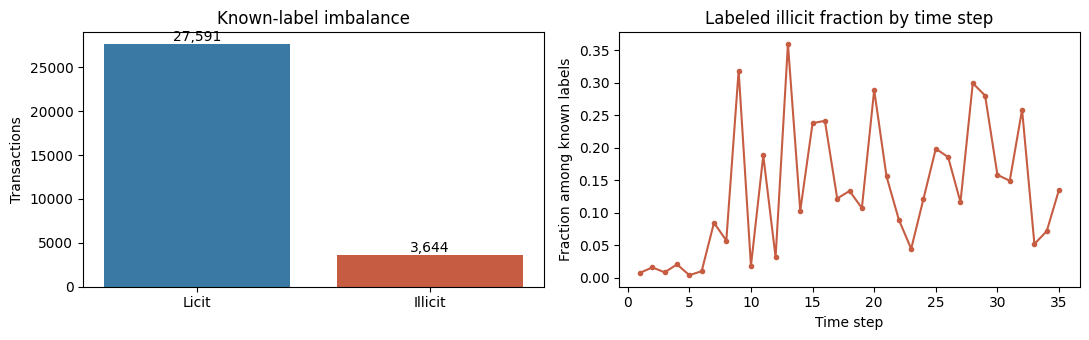

In [3]:
by_time = metadata.groupby('time_step')['label'].agg(total='size', known='count', illicit='sum')
by_time['unknown'] = by_time['total'] - by_time['known']
by_time['illicit_fraction_among_known'] = by_time['illicit'] / by_time['known']
by_time.to_csv(RUN / 'training_time_summary.csv')
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
counts = known['label'].value_counts().reindex([0, 1])
axes[0].bar(['Licit', 'Illicit'], counts, color=['#3979a3', '#c65d42'])
axes[0].set(title='Known-label imbalance', ylabel='Transactions')
for i, count in enumerate(counts):
    axes[0].text(i, count, f'{count:,}', ha='center', va='bottom')
axes[1].plot(by_time.index, by_time['illicit_fraction_among_known'], marker='.', color='#c65d42')
axes[1].set(title='Labeled illicit fraction by time step', xlabel='Time step', ylabel='Fraction among known labels')
fig.tight_layout()
plt.show()

### 2.2 Anonymous features and apparently perfect correlations

I inspect constants and correlations in the early **1–20 training prefix**, without later validation labels. A correlation displayed as 1.00000 can be a rounded near-perfect value. Even an exact Pearson correlation of +1 or −1 establishes an affine relationship only on the observations checked; it does not necessarily mean the two columns contain identical values or that the relationship will persist in future periods. I include equality and affine-residual checks for pairs within a strict 1e-12 correlation tolerance. In this prefix, the four strongest pairs round to 1.00000, but their computed correlations range from approximately 0.999999999165 to 0.999999999744. None meets that stricter tolerance, so the corresponding strict-audit table is empty. This is why I do not use the rounded display as an automatic duplicate-column test.

I do **not** treat perfectly correlated columns as independent information. If two columns remain exact duplicates, one is redundant and removing it is a reasonable simplification. I retained the complete raw feature set as my controlled reference because I had not established a consistent temporal-validation benefit from removing these particular columns. Dropping them solely because of a displayed correlation would change that reference without evidence of improved future performance.

L2 regularization keeps the logistic fit well posed under collinearity, and trees do not invert a feature covariance matrix. This makes retention feasible, but does not make duplicates cost-free: correlated attributes complicate coefficient/importance interpretation and can change random feature-sampling frequencies. I therefore avoid interpreting their individual importance as independent evidence. A dedicated redundancy-removal ablation remains a possible improvement, not an improvement I claim to have demonstrated.

My policy is to exclude identity/target metadata, retain valid numeric attributes initially, and require matched validation evidence before changing the feature set.

In [4]:
early = known.loc[known['time_step'].le(20), FEATURES]
constant_features = early.columns[early.nunique().le(1)].tolist()
correlation = early.corr().abs()
upper = np.triu(np.ones(correlation.shape, dtype=bool), k=1)
i, j = np.where(upper & (correlation.to_numpy() > 0.95))
high_correlation = pd.DataFrame({'feature_a': np.array(FEATURES)[i],
                                 'feature_b': np.array(FEATURES)[j],
                                 'absolute_correlation': correlation.to_numpy()[i, j]})
high_correlation = high_correlation.sort_values('absolute_correlation', ascending=False)
assert not constant_features
print('Constant features in early training:', len(constant_features))
print('Pairs with |Pearson correlation| > 0.95:', len(high_correlation))
display(high_correlation.head(10).round(5))
high_correlation.to_csv(RUN / 'early_training_high_correlations.csv', index=False)
display(pd.DataFrame([
    ['txId', 'Exclude', 'Identity, not a transferable transaction attribute'],
    ['time_step', 'Use for splitting only', 'Predictions must generalize beyond observed periods'],
    ['label', 'Target only', 'Never a predictor; unknown labels excluded'],
    ['feat_1 ... feat_165', 'Retain initially', 'Finite, nonconstant; anonymous meaning is not a removal criterion'],
    ['Repeated feature vectors', 'Retain distinct transaction IDs', 'Different transactions can share the same description']
], columns=['Field / issue', 'Decision', 'Reason']))
near_perfect = high_correlation.loc[high_correlation['absolute_correlation'].ge(1 - 1e-12)]
redundancy_rows = []
for row in near_perfect.itertuples(index=False):
    x, y = early[row.feature_a].to_numpy(), early[row.feature_b].to_numpy()
    slope, intercept = np.linalg.lstsq(np.column_stack([x, np.ones(len(x))]), y, rcond=None)[0]
    redundancy_rows.append({'feature_a': row.feature_a, 'feature_b': row.feature_b,
        'absolute_correlation': row.absolute_correlation, 'identical_values': bool(np.array_equal(x, y)),
        'affine_slope': slope, 'affine_intercept': intercept,
        'max_affine_residual': float(np.max(np.abs(y - (slope*x + intercept))))})
redundancy_audit = pd.DataFrame(redundancy_rows)
print('Near-perfect pairs: full-precision and equality checks on the early prefix')
with pd.option_context('display.precision', 12):
    display(redundancy_audit)
redundancy_audit.to_csv(RUN / 'early_redundancy_audit.csv', index=False)

Constant features in early training: 0
Pairs with |Pearson correlation| > 0.95: 86


,feature_a,feature_b,absolute_correlation
9,feat_23,feat_29,1.0000
10,feat_24,feat_30,1.0000
11,feat_25,feat_31,1.0000
8,feat_22,feat_28,1.0000
31,feat_58,feat_64,1.0000
43,feat_61,feat_67,1.0000
39,feat_60,feat_66,1.0000
34,feat_59,feat_65,1.0000
3,feat_5,feat_14,1.0000
83,feat_152,feat_153,0.9989


,Field / issue,Decision,Reason
0,txId,Exclude,"Identity, not a transferable transaction attri..."
1,time_step,Use for splitting only,Predictions must generalize beyond observed pe...
2,label,Target only,Never a predictor; unknown labels excluded
3,feat_1 ... feat_165,Retain initially,"Finite, nonconstant; anonymous meaning is not ..."
4,Repeated feature vectors,Retain distinct transaction IDs,Different transactions can share the same desc...


Near-perfect pairs: full-precision and equality checks on the early prefix


""


## 3. Establish a fair baseline

I began with **train 1–25 → validate 26–29**, using known labels only. I compared all models on exactly the same transactions and raw attributes. Logistic regression provides a linear reference; random forest and histogram gradient boosting test nonlinear splits and feature interactions.

My initial HGB uses L2=1. I assess stronger regularization separately in the next section. ROC AUC uses continuous scores. The threshold of 0.5 used for descriptive precision/recall/F1 is my reporting convention, not a threshold supplied by the competition.

In [5]:
HGB_PARAMS = dict(learning_rate=0.05, max_iter=250, max_leaf_nodes=31,
                  min_samples_leaf=20, l2_regularization=5.0, max_bins=255,
                  early_stopping=False, random_state=42)

def evaluate(y, probability):
    y = np.asarray(y, dtype=int)
    p = valid_probability(probability, len(y))
    predicted = p >= 0.5
    return {'roc_auc': float(roc_auc_score(y, p)) if np.unique(y).size == 2 else np.nan,
            'average_precision': float(average_precision_score(y, p)) if np.any(y == 1) else np.nan,
            'accuracy_at_0_5': float(accuracy_score(y, predicted)),
            'precision_at_0_5': float(precision_score(y, predicted, zero_division=0)),
            'recall_at_0_5': float(recall_score(y, predicted, zero_division=0)),
            'f1_at_0_5': float(f1_score(y, predicted, zero_division=0)),
            'log_loss': float(log_loss(y, p, labels=[0, 1]))}

def temporal_split(end, stop):
    train = known.loc[known['time_step'].le(end)].copy()
    valid = known.loc[known['time_step'].between(end + 1, stop)].copy()
    assert train['time_step'].max() < valid['time_step'].min()
    assert not train['txId'].isin(valid['txId']).any()
    assert set(train['label']) == set(valid['label']) == {0, 1}
    return train, valid

initial_train, initial_valid = temporal_split(25, 29)
initial_models = {
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(
        C=1.0, solver='lbfgs', max_iter=5000, tol=1e-4, random_state=42)),
    'Random forest': RandomForestClassifier(n_estimators=300, max_depth=16, min_samples_leaf=3,
                                            max_features='sqrt', n_jobs=2, random_state=42),
    'Initial HGB (L2=1)': HistGradientBoostingClassifier(**dict(HGB_PARAMS, l2_regularization=1.0))
}
initial_rows = []
for name, model in initial_models.items():
    with threadpool_limits(limits=2):
        model.fit(initial_train[FEATURES], initial_train['label'])
        p = model.predict_proba(initial_valid[FEATURES])[:, 1]
    initial_rows.append({'model': name, **evaluate(initial_valid['label'], p)})
initial_results = pd.DataFrame(initial_rows)
initial_results.to_csv(RUN / 'initial_model_comparison.csv', index=False)
display(initial_results.round(5))

,model,roc_auc,average_precision,accuracy_at_0_5,precision_at_0_5,recall_at_0_5,f1_at_0_5,log_loss
0,Logistic regression,0.93117,0.73640,0.85924,0.70450,0.73221,0.71809,0.33993
1,Random forest,0.99375,0.98519,0.97478,0.97996,0.91573,0.94676,0.10485
2,Initial HGB (L2=1),0.99531,0.98649,0.97616,0.97255,0.92884,0.95019,0.07509


### Interpretation

I obtained approximately **0.93117** ROC AUC with logistic regression, **0.99375** with random forest and **0.99531** with initial HGB on this split. This supported further work on nonlinear models. It did not establish equally strong performance on more distant future periods, so I continued with HGB while checking stability across time.

## 4. Refine HGB with chronological comparisons

I explored a bounded set of HGB settings. The central comparison below isolates the change from **L2=1** to **L2=5**, keeping other settings fixed. L2 penalizes extreme leaf values and can reduce overly specific updates.

I compare both settings on **1–20 → 21–25** and **1–25 → 26–29**, then inspect their mean and worse-window AUC. I do not select a separate setting for each window.

In [6]:
SHORT_WINDOWS = [(20, 25), (25, 29)]
tuning_rows, tuned_models = [], {}
for end, stop in SHORT_WINDOWS:
    train, valid = temporal_split(end, stop)
    for l2 in [1.0, 5.0]:
        model = HistGradientBoostingClassifier(**dict(HGB_PARAMS, l2_regularization=l2))
        with threadpool_limits(limits=2):
            model.fit(train[FEATURES], train['label'])
            p = model.predict_proba(valid[FEATURES])[:, 1]
        tuned_models[(end, l2)] = (model, p)
        tuning_rows.append({'train_end': end, 'validation_end': stop, 'L2': l2,
                            **evaluate(valid['label'], p)})
tuning_results = pd.DataFrame(tuning_rows)
tuning_summary = tuning_results.groupby('L2').agg(mean_auc=('roc_auc', 'mean'),
    worst_window_auc=('roc_auc', 'min'), mean_average_precision=('average_precision', 'mean'))
tuning_results.to_csv(RUN / 'hgb_regularization_windows.csv', index=False)
display(tuning_results[['train_end', 'validation_end', 'L2', 'roc_auc', 'average_precision']].round(5))
display(tuning_summary.round(5))

,train_end,validation_end,L2,roc_auc,average_precision
0,20,25,1.0,0.93032,0.85957
1,20,25,5.0,0.95975,0.87559
2,25,29,1.0,0.99531,0.98649
3,25,29,5.0,0.99463,0.98457


,mean_auc,worst_window_auc,mean_average_precision
L2,,,
1.0,0.96281,0.93032,0.92303
5.0,0.97719,0.95975,0.93008


### Decision

L2=5 raised my two-window mean AUC from **0.96281 to 0.97719** and improved the worse window, while slightly reducing the easier 26–29 score. I therefore retained 250 iterations, learning rate 0.05, 31 leaves, minimum 20 samples per leaf and L2=5. I disable automatic early stopping so that an internal random split does not replace my chronological evaluation.

## 5. Test several transaction-graph features

I considered more than node degree. The directed edge from a predecessor to a transaction lets me construct:
- **In-degree:** the number of distinct observed predecessor transactions. It is not a wallet identity or the raw number of Bitcoin inputs.
- **Predecessor means:** the mean of each anonymous attribute across immediate predecessors, to describe the source transactions.
- **Two-hop predecessors:** the number of distinct ancestors reachable through exactly two incoming edges, to summarize a wider source structure.
- **Own-minus-predecessor differences:** selected transaction attributes minus their predecessor means, to detect changes relative to upstream activity.

I deduplicate edges and keep unknown-label transactions as attribute/edge context without using their labels. Missing predecessor means are NaN, meaning no observed predecessor; HGB handles those through its learned missing-value branches. For the five difference attributes, I select source columns separately inside each training prefix using direction-free univariate AUC and a fixed correlation filter. Validation labels never enter that selection. This filter diversifies the added differences; it does not remove raw attributes.

I hold HGB settings fixed and compare all graph variants on the same two short windows. Graph context is restricted to the development periods. Same-step predecessor attributes are assumed available in this offline dataset; this would need a separate availability check for real-time deployment.

In [7]:
edges = pd.read_csv(DATA / 'txs_edgelist.csv')
assert edges[['txId1', 'txId2']].notna().all().all()
edge_rows_before = len(edges)
edges = edges.drop_duplicates(['txId1', 'txId2'])
in_degree = edges['txId2'].value_counts()
known['graph_in_degree'] = known['txId'].map(in_degree).fillna(0).astype(int)
HGB_FEATURES = FEATURES + ['graph_in_degree']
assert not {'txId', 'time_step', 'label'}.intersection(HGB_FEATURES)

def incoming_graph_features(attributes, edge_table):
    # Destination-row/source-column adjacency; attributes contains no label.
    assert 'label' not in attributes.columns and attributes['txId'].is_unique
    index = pd.Index(attributes['txId'])
    source = index.get_indexer(edge_table['txId1'])
    destination = index.get_indexer(edge_table['txId2'])
    present = (source >= 0) & (destination >= 0)
    pairs = pd.DataFrame({'source': source[present], 'destination': destination[present]}).drop_duplicates()
    source, destination = pairs['source'].to_numpy(), pairs['destination'].to_numpy()
    times = attributes['time_step'].to_numpy()
    assert np.all(source != destination) and np.all(times[source] <= times[destination])
    adjacency = csr_matrix((np.ones(len(source)), (destination, source)), shape=(len(index), len(index)))
    degree = np.asarray(adjacency.sum(axis=1)).ravel()
    means = adjacency @ attributes[FEATURES].to_numpy(dtype=float)
    np.divide(means, degree[:, None], out=means, where=degree[:, None] != 0)
    means[degree == 0] = np.nan
    result = pd.DataFrame(means, index=index, columns=[f'pred_mean_{name}' for name in FEATURES])
    two_hop = np.zeros(len(index), dtype=np.int64)
    for node in range(len(index)):
        ancestors = set()
        for parent in adjacency.indices[adjacency.indptr[node]:adjacency.indptr[node + 1]]:
            ancestors.update(adjacency.indices[adjacency.indptr[parent]:adjacency.indptr[parent + 1]])
        ancestors.discard(node)
        two_hop[node] = len(ancestors)
    result['graph_two_hop_predecessors'] = two_hop
    return result

def select_difference_sources(train, count=5):
    # Fixed training-only screening rule; no validation labels are accessed.
    positive = train['label'].eq(1)
    n1, n0 = int(positive.sum()), int((~positive).sum())
    scores = []
    for feature in FEATURES:
        ranks = train[feature].rank()
        auc = (ranks[positive].sum() - n1*(n1+1)/2) / (n1*n0)
        scores.append((feature, max(auc, 1-auc)))
    ranking = pd.DataFrame(scores, columns=['feature', 'direction_free_training_auc'])
    ranking = ranking.sort_values('direction_free_training_auc', ascending=False, kind='stable')
    corr = train[FEATURES].corr().abs()
    chosen = []
    for feature in ranking['feature']:
        if train[feature].nunique() > 1 and all(corr.loc[feature, previous] < 0.98 for previous in chosen):
            chosen.append(feature)
        if len(chosen) == count:
            break
    return chosen

extra = incoming_graph_features(context, edges)
graph_data = known.loc[known['time_step'].le(29)].copy()
extra_columns = extra.columns.tolist()
graph_data = pd.concat([graph_data, pd.DataFrame(extra.reindex(graph_data['txId']).to_numpy(),
    index=graph_data.index, columns=extra_columns)], axis=1)
del extra, context
print('Supplied edges:', edge_rows_before, '; distinct edges:', len(edges))
graph_rows, difference_sources = [], {}
for end, stop in SHORT_WINDOWS:
    train = graph_data.loc[graph_data['time_step'].le(end)].copy()
    valid = graph_data.loc[graph_data['time_step'].between(end+1, stop)].copy()
    chosen = select_difference_sources(train)
    difference_sources[end] = chosen
    for frame in [train, valid]:
        for feature in chosen:
            frame[f'delta_{feature}'] = frame[feature] - frame[f'pred_mean_{feature}']
    delta = [f'delta_{feature}' for feature in chosen]
    variants = {
        'Raw attributes': FEATURES,
        'Raw + in-degree': HGB_FEATURES,
        'In-degree + predecessor means': HGB_FEATURES + [f'pred_mean_{f}' for f in FEATURES],
        'In-degree + two-hop count': HGB_FEATURES + ['graph_two_hop_predecessors'],
        'In-degree + five differences': HGB_FEATURES + delta,
        'In-degree + two-hop + differences': HGB_FEATURES + ['graph_two_hop_predecessors'] + delta
    }
    for name, columns in variants.items():
        if name == 'Raw attributes':
            _, probability = tuned_models[(end, 5.0)]
        else:
            with threadpool_limits(limits=2):
                model = HistGradientBoostingClassifier(**HGB_PARAMS).fit(train[columns], train['label'])
                probability = model.predict_proba(valid[columns])[:, 1]
        graph_rows.append({'train_end': end, 'validation_end': stop, 'features': name,
                           'feature_count': len(columns), **evaluate(valid['label'], probability)})
graph_results = pd.DataFrame(graph_rows)
graph_summary = graph_results.groupby('features').agg(feature_count=('feature_count','first'),
    mean_auc=('roc_auc','mean'), worst_window_auc=('roc_auc','min'), mean_average_precision=('average_precision','mean'))
graph_summary['gain_vs_in_degree'] = graph_summary['mean_auc'] - graph_summary.loc['Raw + in-degree','mean_auc']
graph_summary = graph_summary.sort_values('mean_auc', ascending=False)
graph_results.to_csv(RUN / 'graph_feature_ablation_windows.csv', index=False)
graph_summary.to_csv(RUN / 'graph_feature_ablation_summary.csv')
print('Difference source columns selected separately within each training prefix:', difference_sources)
display(graph_summary.round(5))

Supplied edges: 234355 ; distinct edges: 234355


Difference source columns selected separately within each training prefix: {20: ['feat_53', 'feat_55', 'feat_90', 'feat_60', 'feat_47'], 25: ['feat_53', 'feat_55', 'feat_90', 'feat_29', 'feat_47']}


,feature_count,mean_auc,worst_window_auc,mean_average_precision,gain_vs_in_degree
features,,,,,
Raw + in-degree,166,0.97797,0.96181,0.93055,0.00000
Raw attributes,165,0.97719,0.95975,0.93008,-0.00078
In-degree + two-hop count,167,0.97639,0.95869,0.92888,-0.00158
In-degree + two-hop + differences,172,0.97489,0.95526,0.92812,-0.00308
In-degree + five differences,171,0.97422,0.95454,0.92693,-0.00375
In-degree + predecessor means,331,0.96786,0.94102,0.92410,-0.01011


### Why I retained only in-degree

In-degree improved mean AUC from **0.97719 to 0.97797** and improved the worse window, although it lost slightly in the easier window. Adding all predecessor means reduced mean AUC to about **0.96786**. Two-hop counts, five differences and their combination also failed to improve on the in-degree reference across these windows.

I therefore kept only in-degree for HGB and left these additional graph features out of the final model. More graph information was not automatically more predictive: the raw dataset already includes undisclosed neighbor aggregates, so additional aggregates may repeat information or fit period-specific patterns. These are possible explanations, not causal conclusions proved by the ablation. The comparison supports a simpler feature set for this experiment; it does not establish that graph methods are generally ineffective.

## 6. Compare boosting alternatives on the same future periods

### Why I explored CatBoost after HGB

HGB gave me a strong nonlinear baseline. I then compared other boosting implementations rather than assuming that a more complicated architecture would improve it. The table and code below compare fixed **XGBoost, LightGBM, Plain CatBoost and Ordered CatBoost** recipes against HGB on exactly the same labeled rows in four 14-step windows. These are candidate-recipe comparisons, not a claim that any library is universally superior. I kept the original tested settings instead of tuning each library until it won this comparison.

My rationale for continuing with CatBoost is empirical: I compare its AUC, AP and weak-period performance with the other tested boosters. CatBoost's symmetric trees and Ordered training procedure also offer a different learning bias from HGB. The inputs are numeric, so categorical encoding is not the reason for using CatBoost. Ordered boosting is an internal training procedure; it does not replace chronological validation or assign labels to unknown transactions.

### Why I considered blending

Two strong models can mis-rank different transactions. I therefore test whether averaging HGB's probabilities with each alternative helps, using a fixed 50/50 weight before exploring ratios. HGB uses in-degree, whereas CatBoost uses raw attributes, adding another source of diversity. I report individual and blended scores because diversity alone does not guarantee an improvement.

### Comparison design

Each model trains on earlier known labels and predicts the next **14 steps**. No outer-validation labels are used for early stopping. XGBoost and LightGBM use their original in-degree-augmented recipes (166 columns), while CatBoost uses 165 raw attributes; the recipe table makes this difference explicit. I compare mean/worst window AUC and mean/worst single-step AUC, rather than selecting on one favorable window. Overlapping windows and repeated development mean these scores are descriptive, not an untouched holdout estimate.


In [8]:
CAT_PARAMS = dict(iterations=700, depth=6, learning_rate=0.04, l2_leaf_reg=8.0,
                  boosting_type='Ordered', loss_function='Logloss', task_type='CPU',
                  thread_count=2, verbose=False, allow_writing_files=False)

# Fixed recipes from my boosting exploration; no search in this comparison.
XGB_PARAMS = dict(n_estimators=600, learning_rate=0.05, max_depth=6,
    min_child_weight=1, reg_lambda=5.0, reg_alpha=0.0, subsample=0.8,
    colsample_bytree=0.8, max_bin=256, scale_pos_weight=1.0,
    random_state=42, tree_method='hist', device='cpu', objective='binary:logistic',
    eval_metric='auc', n_jobs=2, verbosity=0)
LGB_PARAMS = dict(objective='binary', metric='auc', boosting_type='gbdt',
    learning_rate=0.05, num_leaves=31, max_depth=6, min_data_in_leaf=20,
    lambda_l2=5.0, max_bin=255, seed=42, num_threads=2, deterministic=True,
    force_col_wise=True, verbosity=-1, histogram_pool_size=64.0)
recipe_table = pd.DataFrame([
    {'model':'HGB', 'features':166, 'iterations':250, 'tree_limit':'31 leaves', 'L2':5.0},
    {'model':'XGBoost', 'features':166, 'iterations':600, 'tree_limit':'depth 6', 'L2':5.0},
    {'model':'LightGBM', 'features':166, 'iterations':250, 'tree_limit':'31 leaves / depth 6', 'L2':5.0},
    {'model':'CatBoost Plain / Ordered', 'features':165, 'iterations':700, 'tree_limit':'depth 6', 'L2':8.0}
])
display(recipe_table)
recipe_table.to_csv(RUN/'boosting_recipes.csv', index=False)

ORIGINS = [12, 15, 18, 21]
display(pd.DataFrame({'train_end': ORIGINS, 'validation_start': np.array(ORIGINS)+1,
                      'validation_end': np.array(ORIGINS)+14}))
long_rows, long_steps, long_predictions = [], [], []
for end in ORIGINS:
    training, validation = temporal_split(end, end+14)
    validation_models = fresh(RUN / f'validation_train_1_{end}')
    with threadpool_limits(limits=2):
        hgb = HistGradientBoostingClassifier(**HGB_PARAMS).fit(training[HGB_FEATURES], training['label'])
        hgb_p = hgb.predict_proba(validation[HGB_FEATURES])[:, 1]
    joblib.dump(hgb, validation_models / 'hgb.joblib')
    probabilities = {'hgb_degree': hgb_p}
    for boosting in ['Plain','Ordered']:
        model = CatBoostClassifier(**dict(CAT_PARAMS, boosting_type=boosting, random_seed=42))
        with threadpool_limits(limits=2):
            model.fit(training[FEATURES], training['label'])
            probability = model.predict_proba(validation[FEATURES])[:,1]
        assert model.tree_count_ == 700 and model.feature_names_ == FEATURES
        filename = 'catboost_seed42.cbm' if boosting == 'Ordered' else 'catboost_plain_seed42.cbm'
        model.save_model(str(validation_models / filename))
        probabilities['catboost_plain' if boosting == 'Plain' else 'catboost_ordered'] = probability
    with threadpool_limits(limits=2):
        xgb = XGBClassifier(**XGB_PARAMS).fit(training[HGB_FEATURES], training['label'])
        probabilities['xgboost'] = xgb.predict_proba(validation[HGB_FEATURES])[:, 1]
        dataset = lightgbm.Dataset(training[HGB_FEATURES], label=training['label'],
                                   feature_name=HGB_FEATURES, free_raw_data=True)
        lgb = lightgbm.train(LGB_PARAMS, dataset, num_boost_round=250)
        probabilities['lightgbm'] = lgb.predict(validation[HGB_FEATURES], num_threads=2)
    xgb.save_model(str(validation_models/'xgboost.json'))
    lgb.save_model(str(validation_models/'lightgbm.txt'))
    for alternative in ['xgboost', 'lightgbm']:
        probabilities[f'blend_{alternative}_50'] = 0.5*(hgb_p + probabilities[alternative])
    probabilities['blend_plain_50'] = 0.5*(hgb_p + probabilities['catboost_plain'])
    probabilities['blend_ordered_50'] = 0.5*(hgb_p + probabilities['catboost_ordered'])
    prediction = validation[['txId','time_step','label']].copy()
    prediction['train_end'] = end
    for name, probability in probabilities.items():
        long_rows.append({'train_end':end,'validation_end':end+14,'candidate':name,
                          **evaluate(validation['label'],probability)})
        prediction[name] = probability
        for step in range(end+1,end+15):
            mask = validation['time_step'].eq(step).to_numpy()
            long_steps.append({'train_end':end,'time_step':step,'candidate':name,
                'roc_auc':float(roc_auc_score(validation['label'].to_numpy()[mask],probability[mask]))})
    long_predictions.append(prediction)
    print(f'Completed train 1–{end} → {end+1}–{end+14}')
long_results = pd.DataFrame(long_rows)
long_step_results = pd.DataFrame(long_steps)
repeated_predictions = pd.concat(long_predictions,ignore_index=True)
long_summary = long_results.groupby('candidate').agg(window_auc_mean=('roc_auc','mean'),worst_window_auc=('roc_auc','min'))
step_summary = long_step_results.groupby('candidate').roc_auc.agg(window_step_auc_mean='mean',worst_window_step_auc='min')
long_summary = long_summary.join(step_summary)
long_summary = long_summary.join(long_results.groupby('candidate').average_precision.mean().rename('mean_average_precision'))
long_summary['pooled_repeated_auc'] = [roc_auc_score(repeated_predictions['label'],repeated_predictions[name]) for name in long_summary.index]
long_results.to_csv(RUN/'long_window_results.csv',index=False)
long_step_results.to_csv(RUN/'long_time_step_results.csv',index=False)
long_summary.to_csv(RUN/'long_window_summary.csv')
display(long_summary.round(5))
# Paired windows make the basis for continuing with a candidate visible.
auc_by_window = long_results.pivot(index='train_end',columns='candidate',values='roc_auc')
display(auc_by_window.round(5))
boosting_deltas = auc_by_window[['hgb_degree','catboost_plain','xgboost','lightgbm']].rsub(auc_by_window['catboost_ordered'],axis=0)
boosting_deltas.columns = ['Ordered minus '+name for name in boosting_deltas.columns]
boosting_deltas.to_csv(RUN/'ordered_vs_other_boosters_paired.csv')
print('Ordered CatBoost minus the other individual models; positive favors Ordered:')
display(boosting_deltas.round(5))


,model,features,iterations,tree_limit,L2
0,HGB,166,250,31 leaves,5.0
1,XGBoost,166,600,depth 6,5.0
2,LightGBM,166,250,31 leaves / depth 6,5.0
3,CatBoost Plain / Ordered,165,700,depth 6,8.0


,train_end,validation_start,validation_end
0,12,13,26
1,15,16,29
2,18,19,32
3,21,22,35


Completed train 1–12 → 13–26


Completed train 1–15 → 16–29


Completed train 1–18 → 19–32


Completed train 1–21 → 22–35


,window_auc_mean,worst_window_auc,window_step_auc_mean,worst_window_step_auc,mean_average_precision,pooled_repeated_auc
candidate,,,,,,
blend_lightgbm_50,0.89919,0.87719,0.92391,0.57577,0.84299,0.89800
blend_ordered_50,0.91462,0.89130,0.93145,0.63555,0.85057,0.91540
blend_plain_50,0.89653,0.86554,0.92065,0.60075,0.84254,0.89734
blend_xgboost_50,0.90475,0.87949,0.92643,0.58844,0.84654,0.90236
catboost_ordered,0.91842,0.89465,0.93280,0.66555,0.85198,0.92055
catboost_plain,0.88742,0.84045,0.91451,0.61469,0.83945,0.88984
hgb_degree,0.91018,0.87959,0.92947,0.60251,0.84561,0.90819
lightgbm,0.88742,0.85395,0.91808,0.53888,0.84013,0.88936
xgboost,0.89229,0.85895,0.91962,0.56486,0.84418,0.89300


candidate,blend_lightgbm_50,blend_ordered_50,blend_plain_50,blend_xgboost_50,catboost_ordered,catboost_plain,hgb_degree,lightgbm,xgboost
train_end,,,,,,,,,
12,0.95230,0.95756,0.95491,0.95395,0.96350,0.95576,0.95480,0.94922,0.95243
15,0.88546,0.90922,0.89593,0.89335,0.91995,0.89626,0.89914,0.87060,0.87829
18,0.87719,0.89130,0.86554,0.87949,0.89559,0.85722,0.87959,0.87592,0.87949
21,0.88180,0.90041,0.86973,0.89222,0.89465,0.84045,0.90721,0.85395,0.85895


Ordered CatBoost minus the other individual models; positive favors Ordered:


,Ordered minus hgb_degree,Ordered minus catboost_plain,Ordered minus xgboost,Ordered minus lightgbm
train_end,,,,
12,0.00870,0.00775,0.01108,0.01428
15,0.02080,0.02369,0.04166,0.04934
18,0.01600,0.03836,0.01610,0.01967
21,-0.01256,0.05420,0.03570,0.04070


### What the comparison tells me

The preceding tables show the individual models, equal-weight blends, and paired Ordered-minus-alternative AUC differences. I use the four-window mean together with the worst window to justify the candidate I continue with; I do not interpret a win on a random split as evidence of better future-period performance. The same-window AP column also shows how effectively each candidate prioritizes the minority illicit class.

Long-window scores are much lower than my initial short-window HGB score. Ordered CatBoost improves on Plain CatBoost in this setup (window mean **0.91842 vs 0.88742**); its HGB blend also improves on the Plain blend (**0.91462 vs 0.89653**). Ordered CatBoost also exceeds XGBoost (**0.89229**) and LightGBM (**0.88742**) on mean window AUC. Its worst-window AUC is **0.89465**, versus **0.85895** and **0.85395**, respectively. This is my empirical rationale for continuing with CatBoost instead of those alternative boosting recipes; it is more specific than claiming that CatBoost is always better.

I distinguish **choosing CatBoost as a complementary candidate** from **proving a blend is always better**. Ordered CatBoost alone has a higher four-window mean than its equal HGB blend, and individual periods can favor HGB. I retained blending as a simple candidate and subsequently used competition feedback as well; the final ensemble is not an uncontested temporal-validation winner.


### 6.1 Inspect the latest validation origin

I examine **1–21 → 22–35** separately below. These predictions come from the same fits just used in the four-window comparison. This exposes how individual model choices behave over a long horizon before I add seed averaging.

In [9]:
# The last origin above is 1–21 → 22–35; these are its fitted probabilities.
assert int(training['time_step'].max()) == 21
validation_components = {
    'HGB + in-degree': probabilities['hgb_degree'],
    'Plain CatBoost': probabilities['catboost_plain'],
    'Ordered CatBoost': probabilities['catboost_ordered'],
    'HGB + Plain 50/50': probabilities['blend_plain_50'],
    'HGB + Ordered 50/50': probabilities['blend_ordered_50']
}
latest_window_results = pd.DataFrame([{'candidate':name,**evaluate(validation['label'],p)} for name,p in validation_components.items()])
latest_window_results.to_csv(RUN/'latest_long_window_model_comparison.csv',index=False)
display(latest_window_results.round(5))

,candidate,roc_auc,average_precision,accuracy_at_0_5,precision_at_0_5,recall_at_0_5,f1_at_0_5,log_loss
0,HGB + in-degree,0.90721,0.81124,0.94481,0.94900,0.67174,0.78666,0.31268
1,Plain CatBoost,0.84045,0.78828,0.94703,0.95216,0.68472,0.79659,0.33070
2,Ordered CatBoost,0.89465,0.80932,0.94806,0.96340,0.68302,0.79934,0.32646
3,HGB + Plain 50/50,0.86973,0.79687,0.94695,0.95787,0.67964,0.79512,0.31594
4,HGB + Ordered 50/50,0.90041,0.81113,0.94720,0.96237,0.67795,0.79550,0.31376


### 6.2 A neural alternative I tested

I also investigated deep learning instead of assuming tree ensembles were the only option. Here I reproduce a compact **165 → 64 → 32 → 1 MLP** comparison on the same four future-period windows. I use ReLU, dropout 0.2, AdamW, binary cross-entropy and mini-batches. Standardization is fitted on training rows only. The last three **training** steps select the epoch count (maximum 100, patience 10); I then refit fresh weights on all outer-training rows. Outer-validation labels never select epochs.

I compare the MLP alone and a fixed HGB/MLP probability blend with the tree candidates. This reruns my original small-MLP recipe on the common long-window framework; it is not an exact rerun of every earlier neural stack. The next table is calculated here, so retaining or setting aside this recipe has visible evidence.


In [10]:
torch.set_num_threads(2)
torch.use_deterministic_algorithms(True)
SETTINGS = {"hidden_sizes": [64, 32], "dropout": .2,
            "learning_rate": .001, "weight_decay": .0001,
            "batch_size": 256, "max_epochs": 100, "patience": 10,
            "min_auc_improvement": .0001, "seed": 42,
            "optimizer": "AdamW", "loss": "BCEWithLogitsLoss"}

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

def make_network(settings=SETTINGS):
    h1, h2 = settings["hidden_sizes"]
    return nn.Sequential(nn.Linear(len(FEATURES), h1), nn.ReLU(),
                         nn.Dropout(settings["dropout"]), nn.Linear(h1, h2), nn.ReLU(),
                         nn.Dropout(settings["dropout"]), nn.Linear(h2, 1))

def prepare_inputs(scaler, frame):
    # Training-fitted statistics only; float32 and mini-batches bound RAM usage.
    array = scaler.transform(frame[FEATURES]).astype(np.float32)
    if not np.isfinite(array).all():
        raise ValueError("Nonfinite neural-network inputs")
    return torch.from_numpy(array)

def probability(model, x, batch_size=2048):
    model.eval()  # Disable dropout for inference.
    with torch.inference_mode():
        parts = [torch.sigmoid(model(x[i:i + batch_size]).squeeze(1)).numpy()
                 for i in range(0, len(x), batch_size)]
    result = np.concatenate(parts).astype(float)
    if not np.isfinite(result).all() or not ((result >= 0) & (result <= 1)).all():
        raise ValueError("Invalid predicted probabilities")
    return result

def fit_epochs(train, epochs, monitor=None, settings=SETTINGS):
    """Fit new weights/scaler; optionally choose epoch using internal time window."""
    seed_everything(settings["seed"])
    scaler = StandardScaler().fit(train[FEATURES])
    x = prepare_inputs(scaler, train)
    y = torch.from_numpy(train.label.to_numpy(dtype=np.float32))
    model = make_network(settings)
    optimizer = torch.optim.AdamW(model.parameters(), lr=settings["learning_rate"],
                                 weight_decay=settings["weight_decay"])
    criterion = nn.BCEWithLogitsLoss()
    shuffle = torch.Generator().manual_seed(settings["seed"])
    if monitor is not None:
        monitor_x = prepare_inputs(scaler, monitor)
        monitor_y = torch.from_numpy(monitor.label.to_numpy(dtype=np.float32))
    best_auc, best_epoch, stale = -np.inf, 1, 0
    history = []
    for epoch in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(x), generator=shuffle)
        total_loss = 0.
        for begin in range(0, len(x), settings["batch_size"]):
            ids = order[begin:begin + settings["batch_size"]]
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x[ids]).squeeze(1), y[ids])
            if not torch.isfinite(loss):
                raise RuntimeError("Nonfinite training loss")
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(ids)
        row = {"epoch": epoch, "training_bce_with_dropout": total_loss / len(x)}
        if monitor is not None:
            pred = probability(model, monitor_x)
            auc = roc_auc_score(monitor.label, pred)
            with torch.inference_mode():
                # probability() left the model in evaluation mode (dropout disabled).
                monitor_loss = criterion(model(monitor_x).squeeze(1), monitor_y).item()
            row.update(internal_temporal_auc=float(auc), internal_temporal_bce=monitor_loss)
            if auc > best_auc + settings["min_auc_improvement"]:
                best_auc, best_epoch, stale = float(auc), epoch, 0
            else:
                stale += 1
        history.append(row)
        if monitor is not None and stale >= settings["patience"]:
            break
    return model, scaler, pd.DataFrame(history), best_epoch

def choose_epochs(train):
    """Last three TRAINING time steps are internal monitor; outer validation unused."""
    end = int(train.time_step.max())
    inner_train = train.loc[train.time_step.le(end - 3)]
    monitor = train.loc[train.time_step.between(end - 2, end)]
    for subset in [inner_train, monitor]:
        if set(subset.label.unique()) != {0, 1}:
            raise ValueError("Internal temporal subsets require both classes")
    assert inner_train.time_step.max() < monitor.time_step.min()
    _, _, history, epochs = fit_epochs(inner_train, SETTINGS["max_epochs"], monitor=monitor)
    return epochs, history, {"inner_train": [1, end - 3], "inner_monitor": [end - 2, end]}

neural_rows, neural_steps = [], []
for end in ORIGINS:
    nn_training, nn_validation = temporal_split(end,end+14)
    nn_dir = fresh(RUN/f'mlp_train_1_{end}')
    with threadpool_limits(limits=2):
        epochs, history, inner_split = choose_epochs(nn_training)
        net, scaler, refit_history, _ = fit_epochs(nn_training,epochs)
        mlp_probability = probability(net,prepare_inputs(scaler,nn_validation))
    history.to_csv(nn_dir/'inner_epoch_selection.csv',index=False)
    refit_history.to_csv(nn_dir/'refit_history.csv',index=False)
    (nn_dir/'training.json').write_text(json.dumps({'selected_epochs':epochs,**inner_split,'settings':SETTINGS},indent=2))
    # Reuse predictions already computed on precisely these validation transactions.
    ref = repeated_predictions.loc[repeated_predictions.train_end.eq(end)].set_index('txId').loc[nn_validation.txId]
    np.testing.assert_array_equal(ref.label,nn_validation.label)
    variants = {'mlp':mlp_probability,
                'blend_mlp_50':0.5*(ref.hgb_degree.to_numpy()+mlp_probability)}
    for name,pred in variants.items():
        neural_rows.append({'train_end':end,'candidate':name,**evaluate(nn_validation.label,pred)})
        for step in range(end+1,end+15):
            mask=nn_validation.time_step.eq(step).to_numpy()
            neural_steps.append({'train_end':end,'time_step':step,'candidate':name,
                'roc_auc':roc_auc_score(nn_validation.label.to_numpy()[mask],pred[mask])})
    preds=nn_validation[['txId','time_step','label']].copy()
    preds['mlp']=mlp_probability
    preds.to_csv(nn_dir/'predictions.csv',index=False)
    del net,scaler
    print(f'MLP train 1–{end}: {epochs} epochs selected using training periods only',flush=True)
neural_results=pd.DataFrame(neural_rows)
neural_step_results=pd.DataFrame(neural_steps)
neural_summary=neural_results.groupby('candidate').agg(window_auc_mean=('roc_auc','mean'),
    worst_window_auc=('roc_auc','min'),mean_average_precision=('average_precision','mean'))
neural_summary=neural_summary.join(neural_step_results.groupby('candidate').roc_auc.agg(
    window_step_auc_mean='mean',worst_window_step_auc='min'))
comparison_columns=['window_auc_mean','worst_window_auc','mean_average_precision','window_step_auc_mean','worst_window_step_auc']
neural_comparison=pd.concat([long_summary.loc[['hgb_degree','catboost_ordered','blend_ordered_50'],comparison_columns],neural_summary[comparison_columns]])
neural_results.to_csv(RUN/'neural_window_results.csv',index=False)
neural_step_results.to_csv(RUN/'neural_time_step_results.csv',index=False)
neural_comparison.to_csv(RUN/'neural_vs_tree_summary.csv')
display(neural_comparison.round(5))
neural_deltas=neural_results.pivot(index='train_end',columns='candidate',values='roc_auc').sub(auc_by_window['blend_ordered_50'],axis=0)
print('MLP candidates minus HGB/Ordered 50/50 on the same windows:')
display(neural_deltas.round(5))
neural_deltas.to_csv(RUN/'neural_vs_tree_paired.csv')


MLP train 1–12: 22 epochs selected using training periods only


MLP train 1–15: 27 epochs selected using training periods only


MLP train 1–18: 2 epochs selected using training periods only


MLP train 1–21: 30 epochs selected using training periods only


,window_auc_mean,worst_window_auc,mean_average_precision,window_step_auc_mean,worst_window_step_auc
candidate,,,,,
hgb_degree,0.91018,0.87959,0.84561,0.92947,0.60251
catboost_ordered,0.91842,0.89465,0.85198,0.93280,0.66555
blend_ordered_50,0.91462,0.89130,0.85057,0.93145,0.63555
blend_mlp_50,0.89580,0.83681,0.82769,0.91976,0.60290
mlp,0.85429,0.80395,0.63641,0.88567,0.60655


MLP candidates minus HGB/Ordered 50/50 on the same windows:


candidate,blend_mlp_50,mlp
train_end,,
12,-0.00435,-0.05983
15,-0.01504,-0.04039
18,-0.05449,-0.08735
21,-0.00140,-0.05376


### Decision on neural models

The compact MLP has mean window AUC **0.85429**; its equal HGB blend reaches **0.89580**, below **0.91462** for HGB/Ordered CatBoost. Its worst-window results also do not justify replacing the tree candidates. This direct matched comparison is why I set aside this MLP recipe. My earlier **MLP stacking** submission scored **0.94626**, and an **HGB-to-GAT** stack scored **0.94893**. Those are recorded online observations from different procedures, not locally recalculated scores or the output of the MLP code above. Neither exceeded the final tree blend's **0.95436**.

The added optimization, architecture and stacking choices did not produce a sufficiently reliable benefit in my tested neural approaches. I therefore stopped further neural tuning and retained the tree ensemble. This is a decision about my tested recipes and available evidence, not a claim that neural networks cannot work for transaction graphs. I do not reproduce GAT training here because it is outside this compact development path.


### 6.3 Check weights after choosing blending candidates

With predictions fixed, I scan CatBoost weights **0%, 25%, 50%, 75%, 100%** for both Plain and Ordered CatBoost. These include the individual-model endpoints. The formula is \(p(w)=(1-w)p_{HGB}+wp_{CatBoost}\). This makes the effect of weighting visible without changing model parameters or fitting a flexible stacking layer. The four-window table below uses **seed 42**; I keep it separate from the three-seed ensemble tested next.

These are reused development windows, so I do not automatically treat the locally best weight as a reliable future optimum. I use one ratio across periods, never a separately tuned weight for each time step.


In [11]:
# A small fixed scan reuses probabilities; base models are not refitted per weight.
WEIGHTS = [0.0, 0.25, 0.5, 0.75, 1.0]  # CatBoost weight
weight_rows, weight_steps = [], []
for end, group in repeated_predictions.groupby('train_end',sort=True):
    for cat_name in ['catboost_plain','catboost_ordered']:
        for weight in WEIGHTS:
            scores=(1-weight)*group.hgb_degree.to_numpy()+weight*group[cat_name].to_numpy()
            weight_rows.append({'train_end':end,'catboost_recipe':cat_name,'catboost_weight':weight,
                               **evaluate(group.label,scores)})
            for step in sorted(group.time_step.unique()):
                mask=group.time_step.eq(step).to_numpy()
                weight_steps.append({'train_end':end,'catboost_recipe':cat_name,'catboost_weight':weight,
                    'time_step':int(step),'roc_auc':roc_auc_score(group.label.to_numpy()[mask],scores[mask])})
weight_results=pd.DataFrame(weight_rows)
weight_step_results=pd.DataFrame(weight_steps)
weight_summary=weight_results.groupby(['catboost_recipe','catboost_weight']).agg(
    window_auc_mean=('roc_auc','mean'),worst_window_auc=('roc_auc','min'),mean_average_precision=('average_precision','mean'))
weight_summary=weight_summary.join(weight_step_results.groupby(['catboost_recipe','catboost_weight']).roc_auc.agg(
    window_step_auc_mean='mean',worst_window_step_auc='min'))
weight_results.to_csv(RUN/'single_seed_weight_scan_windows.csv',index=False)
weight_step_results.to_csv(RUN/'single_seed_weight_scan_time_steps.csv',index=False)
weight_summary.to_csv(RUN/'single_seed_weight_scan_summary.csv')
print('Four-window weight scan: Plain and Ordered each use seed 42; endpoints are single models.')
display(weight_summary.round(5))
display(weight_results.pivot(index=['catboost_recipe','catboost_weight'],columns='train_end',values='roc_auc').round(5))


Four-window weight scan: Plain and Ordered each use seed 42; endpoints are single models.


window_auc_mean  worst_window_auc  \
catboost_recipe  catboost_weight                                      
catboost_ordered 0.00                     0.91018           0.87959   
                 0.25                     0.91276           0.88712   
                 0.50                     0.91462           0.89130   
                 0.75                     0.91643           0.89380   
                 1.00                     0.91842           0.89465   
catboost_plain   0.00                     0.91018           0.87959   
                 0.25                     0.90182           0.87099   
                 0.50                     0.89653           0.86554   
                 0.75                     0.89198           0.85544   
                 1.00                     0.88742           0.84045   

                                  mean_average_precision  \
catboost_recipe  catboost_weight                           
catboost_ordered 0.00                            0.84561   
                 0.25                            0.84854   
                 0.50                            0.85057   
                 0.75                            0.85160   
                 1.00                            0.85198   
catboost_plain   0.00                            0.84561   
                 0.25                            0.84348   
                 0.50                            0.84254   
                 0.75                            0.84138   
                 1.00                            0.83945   

                                  window_step_auc_mean  worst_window_step_auc  
catboost_recipe  catboost_weight                                               
catboost_ordered 0.00                          0.92947                0.60251  
                 0.25                          0.93064                0.61559  
                 0.50                          0.93145                0.63555  
                 0.75                          0.93225                0.66029  
                 1.00                          0.93280                0.66555  
catboost_plain   0.00                          0.92947                0.60251  
                 0.25                          0.92414                0.59819  
                 0.50                          0.92065                0.60075  
                 0.75                          0.91766                0.60613  
                 1.00                          0.91451                0.61469

train_end                              12       15       18       21
catboost_recipe  catboost_weight                                    
catboost_ordered 0.00             0.95480  0.89914  0.87959  0.90721
                 0.25             0.95592  0.90466  0.88712  0.90335
                 0.50             0.95756  0.90922  0.89130  0.90041
                 0.75             0.95993  0.91427  0.89380  0.89772
                 1.00             0.96350  0.91995  0.89559  0.89465
catboost_plain   0.00             0.95480  0.89914  0.87959  0.90721
                 0.25             0.95461  0.89654  0.87099  0.88511
                 0.50             0.95491  0.89593  0.86554  0.86973
                 0.75             0.95537  0.89602  0.86109  0.85544
                 1.00             0.95576  0.89626  0.85722  0.84045

## 7. Consolidate the ensemble and final selection

### 7.1 Average three fixed CatBoost seeds

I kept Ordered CatBoost's settings unchanged and trained seeds **42/43/44**. A seed fixes a reproducible random sequence; averaging probabilities can reduce dependence on one realization, but does not guarantee a better future score. HGB remains a single model.

My three-seed candidate did not deliver a consistent improvement across my earlier validation checks. I therefore treated it as exploratory rather than assuming that more seeds would necessarily help, and subsequently observed an online improvement. I distinguish that outcome from a consistent local-validation gain. Below I compare single-seed and three-seed predictions on the same latest long window.

In [12]:
SEEDS = [42, 43, 44]
def component_predictions(frame, folder):
    hgb = joblib.load(folder / 'hgb.joblib')
    assert hgb.get_params() == HistGradientBoostingClassifier(**HGB_PARAMS).get_params()
    result = frame[['txId','time_step']].copy()
    if 'index' in frame:
        result.insert(0,'index',frame['index'])
    with threadpool_limits(limits=2):
        result['hgb_probability'] = hgb.predict_proba(frame[HGB_FEATURES])[:,1]
    for seed in SEEDS:
        model = CatBoostClassifier()
        model.load_model(str(folder/f'catboost_seed{seed}.cbm'))
        assert model.tree_count_ == 700 and model.feature_names_ == FEATURES
        assert model.get_all_params()['boosting_type'] == 'Ordered'
        with threadpool_limits(limits=2):
            result[f'cat_seed_{seed}'] = model.predict_proba(frame[FEATURES])[:,1]
    result['catboost_3seed_mean_probability'] = np.mean([result[f'cat_seed_{seed}'].to_numpy() for seed in SEEDS],axis=0)
    return result

for seed in [43, 44]:
    model = CatBoostClassifier(**CAT_PARAMS, random_seed=seed)
    with threadpool_limits(limits=2):
        model.fit(training[FEATURES], training['label'])
    model.save_model(str(validation_models / f'catboost_seed{seed}.cbm'))
components = component_predictions(validation, validation_models)
cat_mean = components['catboost_3seed_mean_probability'].to_numpy()
hgb_p = components['hgb_probability'].to_numpy()
seed_comparison = {
    'Single-seed Ordered CatBoost': components['cat_seed_42'].to_numpy(),
    'Three-seed Ordered CatBoost': cat_mean,
    'HGB 50% + single-seed Ordered 50%': 0.5 * (hgb_p + components['cat_seed_42'].to_numpy()),
    'HGB 50% + three-seed Ordered 50%': 0.5 * (hgb_p + cat_mean),
    'HGB 25% + three-seed Ordered 75%': 0.25 * hgb_p + 0.75 * cat_mean
}
seed_results = pd.DataFrame([{'candidate': name, **evaluate(validation['label'], p)}
                             for name, p in seed_comparison.items()])
seed_results.to_csv(RUN / 'seed_and_blend_long_window_diagnostic.csv', index=False)
display(seed_results.round(5))

,candidate,roc_auc,average_precision,accuracy_at_0_5,precision_at_0_5,recall_at_0_5,f1_at_0_5,log_loss
0,Single-seed Ordered CatBoost,0.89465,0.80932,0.94806,0.96340,0.68302,0.79934,0.32646
1,Three-seed Ordered CatBoost,0.89984,0.81183,0.94857,0.96431,0.68584,0.80158,0.31864
2,HGB 50% + single-seed Ordered 50%,0.90041,0.81113,0.94720,0.96237,0.67795,0.79550,0.31376
3,HGB 50% + three-seed Ordered 50%,0.90221,0.81206,0.94729,0.96019,0.68020,0.79630,0.31138
4,HGB 25% + three-seed Ordered 75%,0.90074,0.81207,0.94763,0.96105,0.68190,0.79776,0.31410


In [13]:
# Same fixed weight grid, now for the three-seed Ordered ensemble at the latest origin.
three_seed_weight_rows=[]
for weight in WEIGHTS:
    scores=(1-weight)*hgb_p+weight*cat_mean
    step_aucs=[roc_auc_score(validation.loc[validation.time_step.eq(t),'label'],
                scores[validation.time_step.eq(t).to_numpy()]) for t in sorted(validation.time_step.unique())]
    three_seed_weight_rows.append({'catboost_weight':weight,**evaluate(validation.label,scores),
                                  'mean_time_step_auc':np.mean(step_aucs),'worst_time_step_auc':np.min(step_aucs)})
three_seed_weight_results=pd.DataFrame(three_seed_weight_rows)
three_seed_weight_results.to_csv(RUN/'three_seed_weight_scan_latest_window.csv',index=False)
print('Three-seed Ordered weights: diagnostic on train 1–21 → 22–35 only, not a four-window result.')
display(three_seed_weight_results.round(5))


Three-seed Ordered weights: diagnostic on train 1–21 → 22–35 only, not a four-window result.


,catboost_weight,roc_auc,average_precision,accuracy_at_0_5,precision_at_0_5,recall_at_0_5,f1_at_0_5,log_loss,mean_time_step_auc,worst_time_step_auc
0,0.00,0.90721,0.81124,0.94481,0.94900,0.67174,0.78666,0.31268,0.93109,0.77101
1,0.25,0.90424,0.81188,0.94584,0.95234,0.67625,0.79090,0.31045,0.92780,0.75437
2,0.50,0.90221,0.81206,0.94729,0.96019,0.68020,0.79630,0.31138,0.92560,0.73960
3,0.75,0.90074,0.81207,0.94763,0.96105,0.68190,0.79776,0.31410,0.92421,0.73141
4,1.00,0.89984,0.81183,0.94857,0.96431,0.68584,0.80158,0.31864,0.92347,0.72977


### 7.2 Explore the probability weights

After deciding to test blends, I separated **which models to combine** from **how much weight to give them**. For a fixed pair of prediction vectors, I used

\[
p(w)=(1-w)p_{HGB}+w\,\overline{p}_{CatBoost},
\]

where \(w\) is the CatBoost weight. The individual models provide the endpoints; 50/50 is the neutral starting point. I changed weights on probabilities directly, without rank averaging, graph smoothing or retraining the base models for each weight.

The four-window **single-seed Ordered** scan above favors the pure CatBoost endpoint on its mean and worst-window AUC. I therefore do not use it to claim that any blend is locally optimal. The subsequent three-seed table is explicitly a latest-window diagnostic, and its base predictions differ from the single-seed scan.

In my earlier weight study with **Plain CatBoost**, I scanned several ratios. Random validation slightly favored **75% HGB / 25% CatBoost**, but its recorded online AUC was **0.94690**, below the earlier 50/50 blend's **0.94952**. Those historical online scores refer to the earlier Plain model version, not the matched 700-iteration Plain recipe rerun above. That result taught me not to treat a tiny local weight advantage as a reliable online improvement. I did not automatically transfer that ratio to a later Ordered CatBoost ensemble, because changing the base predictions changes the blending problem.

For the final **three-seed Ordered CatBoost** ensemble, I compared the **50% CatBoost / 50% HGB** and **75% CatBoost / 25% HGB** blends, alongside the individual models. Those probability combinations are calculated in the preceding code cell. On the latest long-window diagnostic, 50/50 had AUC about **0.90221**, compared with **0.90074** for 75% CatBoost: the CatBoost-heavy version was not selected because it won that local comparison.

### 7.3 Choose the final submissions

I also used competition leaderboard feedback. I recorded the scores below after submitting the corresponding CSVs; they cannot be recalculated here because the test labels are unavailable. With the same three-seed predictions, the 50/50 blend scored **0.95224**, while increasing the CatBoost weight to 75% scored **0.95436**. This final comparison changed only the probability weight.

I therefore selected both versions as my two final choices. The higher CatBoost weight was my best observed competition result, not proof of a universally optimal ratio. The difference between local and online preferences also reinforces the risk of selecting weights through repeated development and leaderboard feedback. I did not optimize a separate weight for each time step.

In [14]:
selection_history = pd.DataFrame([
    {'submission':'HGB 50% + single-seed Ordered CatBoost 50%','online_roc_auc':0.95128},
    {'submission':'HGB 50% + three-seed Ordered CatBoost 50%','online_roc_auc':0.95224},
    {'submission':'HGB 25% + three-seed Ordered CatBoost 75%','online_roc_auc':0.95436}
])
print('My recorded online results; test labels are unavailable for recalculating these AUCs.')
display(selection_history)
# The final weight is the selected recipe; the diagnostic below does not re-optimize it.
CATBOOST_WEIGHT, HGB_WEIGHT = 0.75, 0.25
selected_p = CATBOOST_WEIGHT * cat_mean + HGB_WEIGHT * hgb_p
window_results = pd.DataFrame([{'train_end': 21, 'validation_start': 22, 'validation_end': 35,
    'train_rows': len(training), 'validation_rows': len(validation), **evaluate(validation['label'], selected_p)}])
frame = validation[['txId', 'time_step', 'label']].copy()
frame['probability_illicit'] = selected_p
frame.to_csv(RUN / 'validation_predictions_train_1_21.csv', index=False)
step_rows = []
for step, group in frame.groupby('time_step'):
    step_rows.append({'train_end': 21, 'time_step': int(step), 'rows': len(group),
                     'illicit': int(group['label'].sum()), **evaluate(group['label'], group['probability_illicit'])})
step_results = pd.DataFrame(step_rows)
window_results.to_csv(RUN / 'validation_window_results.csv', index=False)
step_results.to_csv(RUN / 'validation_time_step_results.csv', index=False)
print('Local diagnostic for my selected recipe: weak periods as well as pooled AUC')
display(step_results[['time_step', 'rows', 'illicit', 'roc_auc', 'average_precision']].round(5))

My recorded online results; test labels are unavailable for recalculating these AUCs.


,submission,online_roc_auc
0,HGB 50% + single-seed Ordered CatBoost 50%,0.95128
1,HGB 50% + three-seed Ordered CatBoost 50%,0.95224
2,HGB 25% + three-seed Ordered CatBoost 75%,0.95436


Local diagnostic for my selected recipe: weak periods as well as pooled AUC


,time_step,rows,illicit,roc_auc,average_precision
0,22,1763,158,0.99915,0.99287
1,23,1187,53,0.95597,0.79537
2,24,1126,137,0.77346,0.50050
3,25,594,118,0.99968,0.99869
4,26,517,96,0.93493,0.88695
5,27,206,24,0.99908,0.99405
6,28,284,85,1.00000,1.00000
7,29,1174,329,0.73141,0.63366
8,30,524,83,0.99238,0.96956
9,31,710,106,0.76037,0.57444


## 8. Refit my final recipe on all known training labels

My final model is:
- **HGB:** 165 raw attributes + in-degree; 250 iterations, learning rate 0.05, 31 leaves, minimum 20 observations per leaf, L2=5, seed 42, early stopping disabled.
- **Ordered CatBoost:** 165 raw attributes; 700 iterations, learning rate 0.04, depth 6, L2=8, seeds 42/43/44.
- **Fusion:** the mean CatBoost probability receives 75% weight and HGB receives 25%.

\[
p_{final}=0.75\left(\frac{p_{CB,42}+p_{CB,43}+p_{CB,44}}{3}\right)+0.25p_{HGB}.
\]

I refit these four classifiers on all **31,235 known-label transactions from steps 1–35**. Unknown targets are excluded. The fitting code is included below; no early stopping, additional feature selection or weight optimization is performed in the final refit.

In [15]:
def fit_final_members(train, folder):
    folder = fresh(folder)
    start = perf_counter()
    with threadpool_limits(limits=2):
        model = HistGradientBoostingClassifier(**HGB_PARAMS).fit(train[HGB_FEATURES],train['label'])
    assert model.n_iter_ == 250
    joblib.dump(model,folder/'hgb.joblib')
    for seed in SEEDS:
        model = CatBoostClassifier(**CAT_PARAMS,random_seed=seed)
        with threadpool_limits(limits=2):
            model.fit(train[FEATURES],train['label'])
        assert model.tree_count_ == 700 and model.feature_names_ == FEATURES
        model.save_model(str(folder/f'catboost_seed{seed}.cbm'))
        print(f'Fitted final Ordered CatBoost seed {seed}')
    record = {'hgb':HGB_PARAMS,'catboost':CAT_PARAMS,'seeds':SEEDS,
              'rows':len(train),'illicit':int(train['label'].sum()),
              'time_steps':[int(train['time_step'].min()),int(train['time_step'].max())],
              'fit_seconds':perf_counter()-start}
    (folder/'training.json').write_text(json.dumps(record,indent=2))
    return record

display(pd.DataFrame([{'model':'HGB','parameters':json.dumps(HGB_PARAMS)},
                     {'model':'Ordered CatBoost','parameters':json.dumps(dict(CAT_PARAMS,seeds=SEEDS))}]))
final_models = RUN/'final_models'
training_record = fit_final_members(known,final_models)
assert training_record['rows'] == 31235 and training_record['illicit'] == 3644
assert training_record['time_steps'] == [1,35]
print(json.dumps(training_record,indent=2))

,model,parameters
0,HGB,"{""learning_rate"": 0.05, ""max_iter"": 250, ""max_..."
1,Ordered CatBoost,"{""iterations"": 700, ""depth"": 6, ""learning_rate..."


Fitted final Ordered CatBoost seed 42


Fitted final Ordered CatBoost seed 43


Fitted final Ordered CatBoost seed 44
{
  "hgb": {
    "learning_rate": 0.05,
    "max_iter": 250,
    "max_leaf_nodes": 31,
    "min_samples_leaf": 20,
    "l2_regularization": 5.0,
    "max_bins": 255,
    "early_stopping": false,
    "random_state": 42
  },
  "catboost": {
    "iterations": 700,
    "depth": 6,
    "learning_rate": 0.04,
    "l2_leaf_reg": 8.0,
    "boosting_type": "Ordered",
    "loss_function": "Logloss",
    "task_type": "CPU",
    "thread_count": 2,
    "verbose": false,
    "allow_writing_files": false
  },
  "seeds": [
    42,
    43,
    44
  ],
  "rows": 31235,
  "illicit": 3644,
  "time_steps": [
    1,
    35
  ],
  "fit_seconds": 231.69815349997953
}


## 9. Predict the test set and generate submission files

I now read the test features, check their schema and construct the same in-degree feature. I predict every test row, align predictions to the sample submission's `index` order, and export `index,target` with probability scores in [0,1]. No test labels are used.

I save both selected weights to a new run directory. I also record the checksums of my selected CSVs directly below so that I can check exact reproduction without loading any earlier submission file. A different platform may introduce harmless floating-point changes, so an exact-byte checksum is reported separately from the format checks.

In [16]:
test = pd.read_csv(DATA/'test.csv')
sample = read_csv(DATA/'sample_submission.csv')
assert 'label' not in test and 'target' not in test
assert len(test) == len(sample) == 15329
assert test['txId'].is_unique and test['index'].is_unique and sample['index'].is_unique
assert test['time_step'].between(36,49).all()
assert np.isfinite(test[FEATURES].to_numpy()).all()
np.testing.assert_array_equal(test['index'],sample['index'])
test['graph_in_degree'] = test['txId'].map(in_degree).fillna(0).astype(int)
components = component_predictions(test,final_models)
submission_dir = fresh(RUN/'submission')
selected_checksums = {
    'submission_cb75_hgb25.csv':'4cf7ba3c7135aa57729f6a8125c273d043a4732c290f0a99b2162b6154071dea',
    'submission_cb50_hgb50.csv':'ac95cb227ec6ccb8c1897a444bb8b68c8e0c0bb53c8a2337638b799ba2d136bd'
}
checks = []
for weight,name in [(0.75,'submission_cb75_hgb25.csv'),(0.50,'submission_cb50_hgb50.csv')]:
    score = weight*components['catboost_3seed_mean_probability'].to_numpy() + (1-weight)*components['hgb_probability'].to_numpy()
    aligned = pd.Series(valid_probability(score,len(test)),index=components['index']).loc[sample['index']].to_numpy()
    output = pd.DataFrame({'index':sample['index'],'target':aligned})
    assert output.columns.tolist() == ['index','target'] and not output.isna().any().any()
    assert output['index'].is_unique and output['target'].between(0,1).all()
    path = submission_dir/name
    output.to_csv(path,index=False)
    restored = read_csv(path)
    np.testing.assert_array_equal(restored['index'],sample['index'])
    np.testing.assert_array_equal(restored['target'],aligned)
    checks.append({'file':name,'rows':len(output),'catboost_weight':weight,
                   'sha256':sha256(path),'exact_selected_csv_match':sha256(path)==selected_checksums[name]})
components.to_csv(submission_dir/'prediction_components.csv',index=False)
(submission_dir/'verification.json').write_text(json.dumps({'files':checks,'uploaded':False},indent=2))
submission_path = submission_dir/'submission_cb75_hgb25.csv'
submission = read_csv(submission_path)
exact_csv_match = checks[0]['exact_selected_csv_match']
print('My top-submission CSV:',submission_path.relative_to(ROOT))
display(pd.DataFrame(checks))
display(submission.head())

My top-submission CSV: outputs/notebook_e1155697/20261025T092645Z_47b594ee/submission/submission_cb75_hgb25.csv


,file,rows,catboost_weight,sha256,exact_selected_csv_match
0,submission_cb75_hgb25.csv,15329,0.75,4cf7ba3c7135aa57729f6a8125c273d043a4732c290f0a...,True
1,submission_cb50_hgb50.csv,15329,0.50,ac95cb227ec6ccb8c1897a444bb8b68c8e0c0bb53c8a23...,True


,index,target
0,0,0.000915
1,1,0.002269
2,2,0.001162
3,3,0.000285
4,4,0.000261


## 10. Findings and reflection

My development path was **data audit → linear baseline → nonlinear trees → stronger HGB regularization → graph-feature ablations → longer-horizon booster and MLP comparisons → seed averaging and probability blending**.

I learned that a very high short-window AUC did not guarantee equivalent future performance. Anonymous features could still be assessed using quality checks and matched comparisons, without assigning them invented meanings. Additional graph features and larger ensembles needed evidence; most of the graph additions did not earn a place in the final feature set.

I also explored MLP and graph-neural stacking, but their tested results did not justify continuing that direction in this project. I kept the final model as a tree ensemble. Weight selection was similarly empirical: I compared fixed ratios and retained the final versions using observed competition performance, while acknowledging that local and online preferences differed. I used repeated development and leaderboard feedback, so I cannot treat the best score as an unbiased estimate for a completely new deployment period. An independent future labeled dataset would be needed for that assessment.

All code required for the core development comparisons and final submission is in this notebook; the compact MLP is retrained here, while larger discarded neural stacks are summarized separately. The only pre-existing input files required are the four raw competition CSVs. I also reload models and CSVs created within the current run to check serialization and output integrity; no earlier project results or models are needed.

In [17]:
summary = {'student_number':'e1155697','training_rows':len(known),
           'training_illicit':int(known['label'].sum()),'validation_origins':ORIGINS,
           'catboost_weight':CATBOOST_WEIGHT,'hgb_weight':HGB_WEIGHT,
           'recorded_online_auc':0.95436,
           'generated_submission':str(submission_path.relative_to(ROOT)),
           'submission_sha256':sha256(submission_path),
           'exact_csv_byte_match':exact_csv_match,
           'standalone_notebook':True,'development_storyline_reproduced':True,
           'boosting_comparison_candidates':list(long_summary.index),
           'neural_comparison_candidates':list(neural_summary.index),
           'weight_grid':WEIGHTS,
           'initial_model_auc':dict(zip(initial_results['model'],initial_results['roc_auc'])),
           'total_elapsed_seconds':perf_counter()-started,
           'reused_development_data':True,'uploaded':False}
(RUN/'notebook_verification.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))

{
  "student_number": "e1155697",
  "training_rows": 31235,
  "training_illicit": 3644,
  "validation_origins": [
    12,
    15,
    18,
    21
  ],
  "catboost_weight": 0.75,
  "hgb_weight": 0.25,
  "recorded_online_auc": 0.95436,
  "generated_submission": "outputs/notebook_e1155697/20261025T092645Z_47b594ee/submission/submission_cb75_hgb25.csv",
  "submission_sha256": "4cf7ba3c7135aa57729f6a8125c273d043a4732c290f0a99b2162b6154071dea",
  "exact_csv_byte_match": true,
  "standalone_notebook": true,
  "development_storyline_reproduced": true,
  "boosting_comparison_candidates": [
    "blend_lightgbm_50",
    "blend_ordered_50",
    "blend_plain_50",
    "blend_xgboost_50",
    "catboost_ordered",
    "catboost_plain",
    "hgb_degree",
    "lightgbm",
    "xgboost"
  ],
  "neural_comparison_candidates": [
    "blend_mlp_50",
    "mlp"
  ],
  "weight_grid": [
    0.0,
    0.25,
    0.5,
    0.75,
    1.0
  ],
  "initial_model_auc": {
    "Logistic regression": 0.9311721004482102,
    "R